In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("seeds_data.csv")

display(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nClass counts (for later evaluation only):")
print(df["Class"].value_counts().sort_index())

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


Dataset shape: (210, 8)
Columns: ['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5', 'Feature_6', 'Feature_7', 'Class']

Class counts (for later evaluation only):
Class
1    70
2    70
3    70
Name: count, dtype: int64


In [3]:
X_raw = df.drop(columns=["Class"]).to_numpy(dtype=float)
y_true = df["Class"].to_numpy()  # Keep separate; do not use for fitting

feature_names = df.drop(columns=["Class"]).columns

mean = X_raw.mean(axis=0)
std = X_raw.std(axis=0)
X = (X_raw - mean) / std

print("Feature matrix shape:", X.shape)
print("Target array shape (evaluation only):", y_true.shape)
print("Standardized means:", np.round(X.mean(axis=0), 4))
print("Standardized standard deviations:", np.round(X.std(axis=0), 4))

Feature matrix shape: (210, 7)
Target array shape (evaluation only): (210,)
Standardized means: [-0.  0.  0. -0. -0. -0. -0.]
Standardized standard deviations: [1. 1. 1. 1. 1. 1. 1.]


In [4]:
def kmeans(X, k, max_iter=300, seed=42):
    rng = np.random.default_rng(seed)
    centers = X[rng.choice(len(X), size=k, replace=False)].copy()

    for _ in range(max_iter):
        # Calculate distance from every point to every center
        distances = np.sqrt(
            ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        )
        labels = np.argmin(distances, axis=1)

        # Recalculate centers as means of assigned points
        new_centers = centers.copy()
        for j in range(k):
            points = X[labels == j]
            if len(points) > 0:
                new_centers[j] = points.mean(axis=0)
            else:
                # Reinitialize an empty cluster
                new_centers[j] = X[rng.integers(len(X))]

        if np.allclose(centers, new_centers):
            centers = new_centers
            break

        centers = new_centers

    # Reassign points using the final centers
    distances = np.sqrt(
        ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    )
    labels = np.argmin(distances, axis=1)

    # Within-cluster sum of squared distances (inertia)
    inertia = 0.0
    for j in range(k):
        points = X[labels == j]
        inertia += ((points - centers[j]) ** 2).sum()

    return labels, centers, inertia

K=1, inertia=1470.000
K=2, inertia=659.936
K=3, inertia=430.817
K=4, inertia=372.894
K=5, inertia=350.919
K=6, inertia=303.400
K=7, inertia=278.665
K=8, inertia=240.249


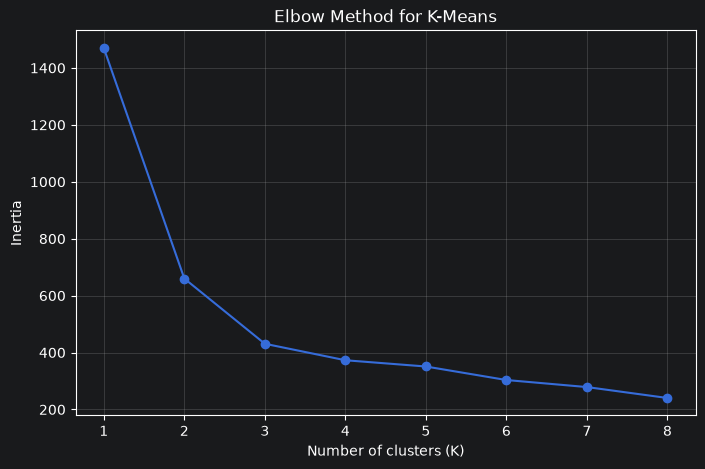

In [5]:
k_values = range(1, 9)
inertias = []

for k in k_values:
    labels_k, centers_k, inertia_k = kmeans(X, k)
    inertias.append(inertia_k)
    print(f"K={k}, inertia={inertia_k:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
k = 3
kmeans_labels, centers, final_inertia = kmeans(X, k)

print("Final inertia:", round(final_inertia, 3))
print("\nCluster sizes:")
print(pd.Series(kmeans_labels, name="Cluster").value_counts().sort_index())

print("\nCluster centers in standardized units:")
display(pd.DataFrame(centers, columns=feature_names).round(3))

centers_original = centers * std + mean
print("\nCluster centers in original feature units:")
display(pd.DataFrame(centers_original, columns=feature_names).round(3))

Final inertia: 430.817

Cluster sizes:
Cluster
0    69
1    70
2    71
Name: count, dtype: int64

Cluster centers in standardized units:


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7
0,1.227,1.236,0.533,1.220,1.130,-0.047,1.280
1,-0.167,-0.204,0.475,-0.303,-0.012,-0.682,-0.640
2,-1.027,-1.000,-0.986,-0.887,-1.087,0.718,-0.613



Cluster centers in original feature units:


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7
0,18.408,16.169,0.884,6.168,3.685,3.630,6.036
1,14.362,14.294,0.882,5.495,3.254,2.677,5.094
2,11.866,13.256,0.848,5.236,2.849,4.777,5.107


In [7]:
def pca(X):
    X_centered = X - X.mean(axis=0)
    covariance = np.cov(X_centered, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]
    components = eigenvectors[:, order[:2]]
    X_pca = X_centered @ components
    explained = eigenvalues[order[:2]].sum() / eigenvalues.sum()
    return X_pca, explained

X_pca, explained_variance = pca(X)
print(f"Variance explained by first two principal components: {explained_variance * 100:.2f}%")

Variance explained by first two principal components: 88.98%


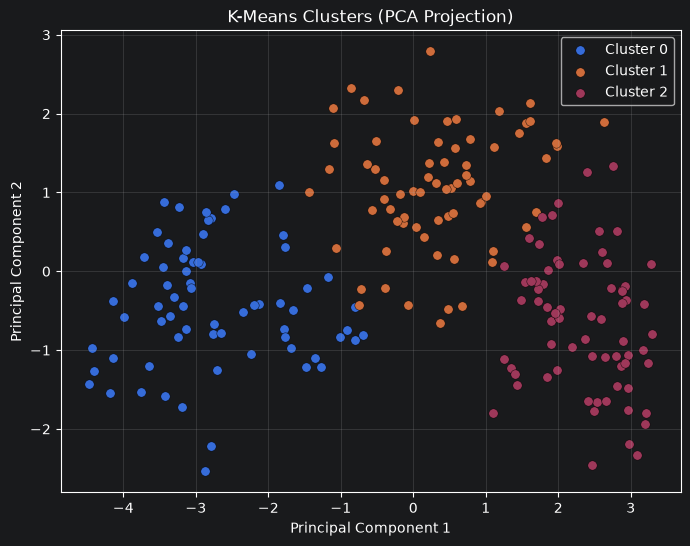

In [8]:
plt.figure(figsize=(8, 6))
for cluster in np.unique(kmeans_labels):
    mask = kmeans_labels == cluster
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        s=45, label=f"Cluster {cluster}", edgecolors="black", linewidths=0.3
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (PCA Projection)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

Predicted clusters versus true classes:


True class,1,2,3
Predicted cluster,,,
0,2,67,0
1,63,3,4
2,5,0,66


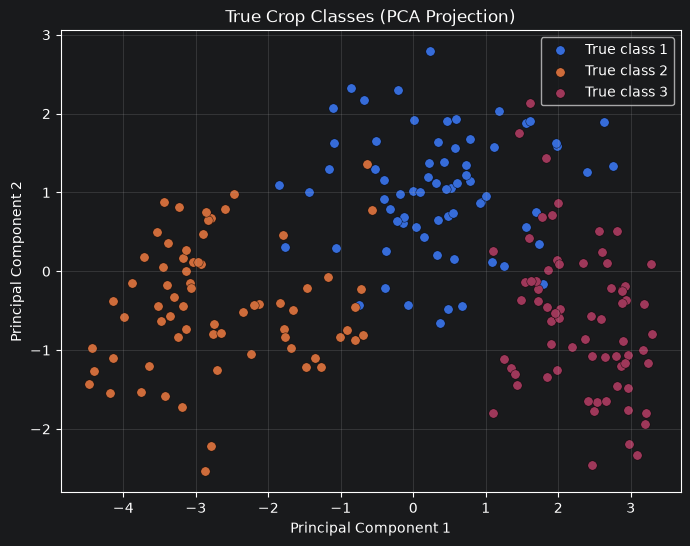

In [9]:
print("Predicted clusters versus true classes:")
display(pd.crosstab(
    pd.Series(kmeans_labels, name="Predicted cluster"),
    pd.Series(y_true, name="True class")
))

plt.figure(figsize=(8, 6))
for crop in np.unique(y_true):
    mask = y_true == crop
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        s=45, label=f"True class {crop}", edgecolors="black", linewidths=0.3
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("True Crop Classes (PCA Projection)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()